# Databases - Spatial

This tutorial covers the spatial databases of `plans`. Unlike `SemiSpatialDB`, they keep the geometries inside the database file, a GeoPackage, so records and places travel together and open in any GIS. There is one class per kind of geometry, each with its own layer and record key:

| Class | Layer | Geometry | Record key |
|---|---|---|---|
| `ZonesDB` | `zones` | polygons | `zone_id` |
| `PathsDB` | `paths` | lines | `path_id` |
| `SitesDB` | `sites` | points | `site_id` |
| `SpatialDB` | `features` | any, mixed | `feature_id` |

The examples are a rainfall grid, a river network and a few weather stations.

```{seealso}
Check out the {doc}`Databases - Station networks <databases_02_semispatial>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import LineString, Point, box

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import ZonesDB, PathsDB, SitesDB, SpatialDB
from plans.datasets.analyst import GeoUnivar

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


All examples use monthly data from 2016 to 2020, and the same helper to write a specs file:

In [2]:
rng = np.random.default_rng(seed=3)  # ensure reproducibility
dates = pd.date_range(start="2016-01-01", end="2020-12-01", freq="MS")
season = np.cos(2 * np.pi * (dates.month - 1) / 12)


def write_specs(file_specs, specs):
    # each spec is (name, abstract, variable, statistic, source, extent)
    rows = [
        {
            "name": name,
            "abstract": abstract,
            "method": "synthetic",
            "timestep": "1M",
            "extent": extent,
            "scale": 1,
            "offset": 0,
            "start": "2016-01-01",
            "end": None,
            "variable_name": variable,
            "statistic_name": statistic,
            "source_name": source,
        }
        for name, abstract, variable, statistic, source, extent in specs
    ]
    file_specs.write_text(json.dumps(rows, indent=2), encoding="utf-8")
    return file_specs

## Zones: a rainfall grid

Gridded products, such as satellite rainfall, are polygons in a regular grid. Lets make an 8 by 6 grid of half-degree cells, each with a unique `name`:

In [3]:
cells = []
for row in range(6):
    for col in range(8):
        x0, y0 = -54.0 + 0.5 * col, -29.0 - 0.5 * (row + 1)
        cells.append({"name": f"R{row + 1}C{col + 1}", "geometry": box(x0, y0, x0 + 0.5, y0 + 0.5)})
grid = gpd.GeoDataFrame(data=cells, crs="EPSG:4674")

file_grid = OUTPUT_DIR / "grid.gpkg"
grid.to_file(filename=file_grid, layer="grid", driver="GPKG")
grid.head()

,name,geometry
0,R1C1,"POLYGON ((-53.5 -29.5, -53.5 -29, -54 -29, -54..."
1,R1C2,"POLYGON ((-53 -29.5, -53 -29, -53.5 -29, -53.5..."
2,R1C3,"POLYGON ((-52.5 -29.5, -52.5 -29, -53 -29, -53..."
3,R1C4,"POLYGON ((-52 -29.5, -52 -29, -52.5 -29, -52.5..."
4,R1C5,"POLYGON ((-51.5 -29.5, -51.5 -29, -52 -29, -52..."


A spatial database is created from the usual setup plus a `[spatial]` section, with the source `file` of the geometries and, if the file has several, the `layer`. The database must be a `.gpkg` file. Each zone gets a generated `id`, which is only stable inside this file, so the `name` is the reference to use elsewhere:

In [4]:
file_specs = write_specs(
    file_specs=OUTPUT_DIR / "grid_specs.json",
    specs=[("PPT_MONTHLY_GRID", "Monthly rainfall per grid cell", "precipitation", "sum", "CHIRPS v2.0", "cell")],
)
zdb = ZonesDB(name="Grid")
zdb.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "grid_db.gpkg")},
        "specs": {"path": str(file_specs)},
        "spatial": {"file": str(file_grid), "layer": "grid"},
    },
    overwrite=True,
)
print(zdb.inspect_schema(table="records", quiet=True))

[Grid]
  records  (0 rows)
    id                   INTEGER
    inserted             INTEGER
    datetime             INTEGER
    value                REAL
    flag_value           INTEGER
    spec_id              INTEGER
    zone_id              INTEGER



Rainfall grows to the east. Records can name their zone with `zone_name` instead of `zone_id`; the database resolves it, and refuses names it does not know:

In [5]:
frames = []
for cell in grid.itertuples():
    east = cell.geometry.centroid.x + 54.0  # 0 to 4 degrees
    mean_ppt = (90 + 20 * east) * (1 - 0.3 * season)
    frames.append(pd.DataFrame({"datetime": dates, "value": rng.gamma(shape=6, scale=mean_ppt / 6), "zone_name": cell.name}))
df = pd.concat(frames, ignore_index=True)

zdb.insert_records(dataframe=df, spec_name="PPT_MONTHLY_GRID", flag=1)
zdb.query_records(query_dict={"zone_name": ["R1C1", "R1C8"], "start": "2016-01-01", "end": "2016-02-01"})[["datetime", "value", "zone_id"]]

,datetime,value,zone_id
0,2016-01-01 00:00:00+00:00,133.506982,1
1,2016-02-01 00:00:00+00:00,78.772256,1
2,2016-01-01 00:00:00+00:00,53.506193,8
3,2016-02-01 00:00:00+00:00,44.953056,8


The geometries come back with `.get_features()`, with `id` as the first column. It matches `zone_id` in the records, so a mean per zone joins straight to its cell:

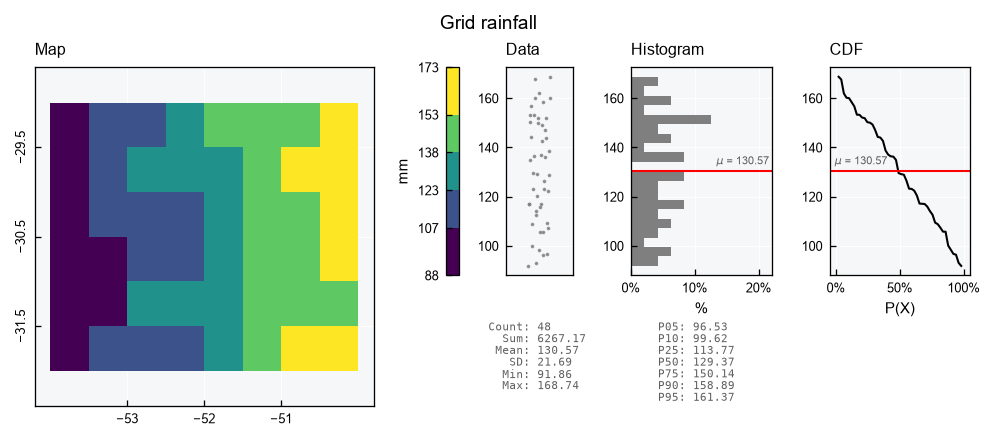

In [6]:
df = zdb.query_records(query_dict={"spec_name": "PPT_MONTHLY_GRID"})
mean_monthly = df.groupby("zone_id")["value"].mean().rename("ppt_mean")
zones = zdb.get_features().merge(mean_monthly, left_on="id", right_index=True)

gv = GeoUnivar(name="Grid rainfall", alias="PPT")
gv.varname = "Mean monthly rainfall"
gv.units = "mm"
gv.set_data(input_df=zones, input_varfield="ppt_mean")
gv.view()

In [7]:
zdb.close()

## Paths: a river network

Lines hold data that flows along them, such as streamflow in a river. Lets build a small network: a main river in four reaches, from west to east, and three tributaries. Each reach has the drainage area at its downstream end:

In [8]:
nodes = {
    "a": (-53.5, -30.0), "b": (-52.8, -30.1), "c": (-52.0, -30.0), "d": (-51.2, -30.2), "outlet": (-50.4, -30.1),
    "t1": (-52.9, -29.2), "t2": (-52.1, -30.9), "t3": (-51.0, -29.3),
}
reaches = [
    ("M1", "a", "b", 800), ("M2", "b", "c", 1900), ("M3", "c", "d", 3200), ("M4", "d", "outlet", 4800),
    ("T1", "t1", "b", 500), ("T2", "t2", "c", 700), ("T3", "t3", "d", 900),
]
rivers = gpd.GeoDataFrame(
    data={
        "name": [r[0] for r in reaches],
        "area_km2": [r[3] for r in reaches],
        "geometry": [LineString([nodes[r[1]], nodes[r[2]]]) for r in reaches],
    },
    crs="EPSG:4674",
)
file_rivers = OUTPUT_DIR / "rivers.gpkg"
rivers.to_file(filename=file_rivers, driver="GPKG")
rivers

,name,area_km2,geometry
0,M1,800,"LINESTRING (-53.5 -30, -52.8 -30.1)"
1,M2,1900,"LINESTRING (-52.8 -30.1, -52 -30)"
2,M3,3200,"LINESTRING (-52 -30, -51.2 -30.2)"
3,M4,4800,"LINESTRING (-51.2 -30.2, -50.4 -30.1)"
4,T1,500,"LINESTRING (-52.9 -29.2, -52.8 -30.1)"
5,T2,700,"LINESTRING (-52.1 -30.9, -52 -30)"
6,T3,900,"LINESTRING (-51 -29.3, -51.2 -30.2)"


Only the `name` and the geometry enter the layer by default. Any other column must be declared in a `columns_map`, as `{layer column: source column}`, so the drainage area is declared in the setup below.

Monthly streamflow is the drainage area times a runoff depth, converted to cubic meters per second. Runoff shares one noise for the whole network, so wet months are wet everywhere:

In [9]:
file_specs = write_specs(
    file_specs=OUTPUT_DIR / "rivers_specs.json",
    specs=[("Q_MONTHLY", "Monthly mean streamflow per reach", "standard streamflow", "mean", "ANA", "reach")],
)
pdb = PathsDB(name="Rivers")
pdb.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "rivers_db.gpkg")},
        "specs": {"path": str(file_specs)},
        "spatial": {"file": str(file_rivers), "columns_map": {"area_km2": "area_km2"}},
    },
    overwrite=True,
)

runoff_mm = 40 * (1 - 0.4 * season) * rng.gamma(shape=5, scale=0.2, size=len(dates))
seconds = dates.days_in_month * 86400
frames = []
for reach in rivers.itertuples():
    flow = reach.area_km2 * 1e6 * runoff_mm / 1000 / seconds
    frames.append(pd.DataFrame({"datetime": dates, "value": flow, "path_name": reach.name}))
pdb.insert_records(dataframe=pd.concat(frames, ignore_index=True), spec_name="Q_MONTHLY", flag=1)

Lines go through `GeoUnivar` too. For lines, the edge color is the line color, so the `edgecolor_map` key must be `None` to let the color map paint them. Flow grows downstream:

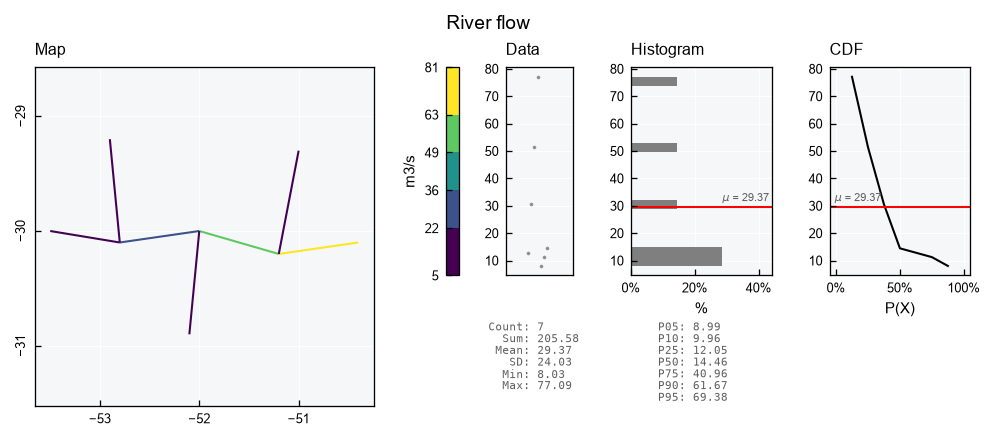

In [10]:
df = pdb.query_records(query_dict={"spec_name": "Q_MONTHLY"})
mean_flow = df.groupby("path_id")["value"].mean().rename("q_mean")
paths = pdb.get_features().merge(mean_flow, left_on="id", right_index=True)

gv = GeoUnivar(name="River flow", alias="Q")
gv.varname = "Mean streamflow"
gv.units = "m3/s"
gv.set_data(input_df=paths, input_varfield="q_mean")
gv.view_specs["edgecolor_map"] = None
gv.view()

In wide format, the reaches of the main river show the flow building up along the way:

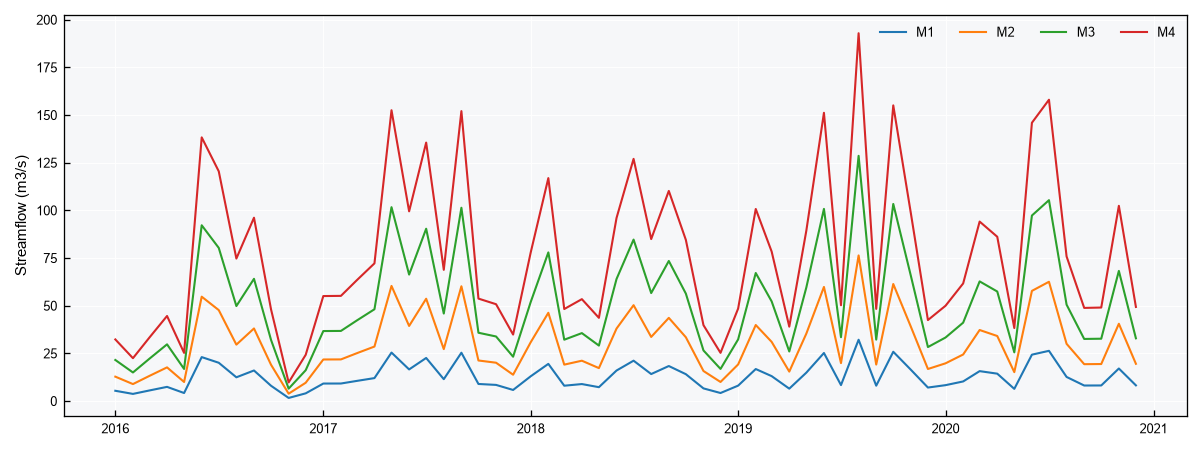

In [11]:
wide = pdb.query_records(query_dict={"path_name": ["M1", "M2", "M3", "M4"], "wide": True})
names = pdb.get_features().set_index("id")["name"]

fig, ax = plt.subplots(figsize=(8, 3))
for (spec, path_id), series in wide.items():
    ax.plot(series.index, series.values, lw=1, label=names[path_id])
ax.set_ylabel("Streamflow (m3/s)")
ax.legend(ncols=4, frameon=False)
plt.tight_layout()
plt.show()

In [12]:
pdb.close()

## Sites: weather stations

Points are sites, such as weather stations. Sources rarely call their key `name`, so the `columns_map` can also point it to another column, here `station`. The key must be unique, and text or integer values are stored as text. The layer only accepts points; any other geometry is refused:

In [13]:
stations = gpd.GeoDataFrame(
    data={"station": ["Coast", "Valley", "Plateau"], "operator": ["INMET", "INMET", "ANA"]},
    geometry=gpd.points_from_xy(x=[-50.5, -52.0, -53.2], y=[-30.2, -30.0, -28.9]),
    crs="EPSG:4674",
)
file_stations = OUTPUT_DIR / "sites.gpkg"
stations.to_file(filename=file_stations, driver="GPKG")

file_specs = write_specs(
    file_specs=OUTPUT_DIR / "sites_specs.json",
    specs=[("TAS_MONTHLY", "Monthly mean air temperature", "surface air temperature", "mean", "INMET", "station")],
)
sdb = SitesDB(name="Stations")
sdb.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "sites_db.gpkg")},
        "specs": {"path": str(file_specs)},
        "spatial": {"file": str(file_stations), "columns_map": {"name": "station", "operator": "operator"}},
    },
    overwrite=True,
)
try:
    sdb.insert_features(gdf=grid.head(1)[["name", "geometry"]])
except ValueError as error:
    print(error)

Geometry type(s) ['Polygon'] not accepted in sites. Valid: ['Point']


Networks grow. The `.insert_features()` method adds sites later. Here, a new station comes in UTM coordinates; it is reprojected to the CRS of the layer, and gets the next id. It takes a `columns_map` as well; layer columns left out stay empty, and columns the layer does not have are refused:

In [14]:
new_station = gpd.GeoDataFrame(
    data={"name": ["Ridge"]},
    geometry=gpd.points_from_xy(x=[450000], y=[6720000]),
    crs="EPSG:31982",  # SIRGAS 2000 / UTM zone 22S
)
sdb.insert_features(gdf=new_station)
sdb.get_features()

,id,name,operator,geometry
0,1,Coast,INMET,POINT (-50.5 -30.2)
1,2,Valley,INMET,POINT (-52 -30)
2,3,Plateau,ANA,POINT (-53.2 -28.9)
3,4,Ridge,NaN,POINT (-51.5166 -29.64896)


Records of all four stations, named by `site_name`:

In [15]:
frames = []
for name, base in {"Coast": 20, "Valley": 19, "Plateau": 15, "Ridge": 13}.items():
    tas = base + 5 * season + rng.normal(scale=0.8, size=len(dates))
    frames.append(pd.DataFrame({"datetime": dates, "value": tas, "site_name": name}))
sdb.insert_records(dataframe=pd.concat(frames, ignore_index=True), spec_name="TAS_MONTHLY", flag=1)

wide = sdb.query_records(query_dict={"wide": True})
wide.columns = sdb.get_features().set_index("id").loc[wide.columns.get_level_values("site_id"), "name"]
wide.head()

name,Coast,Valley,Plateau,Ridge
datetime,,,,
2016-01-01 00:00:00+00:00,24.976864,23.332622,18.968884,17.892839
2016-02-01 00:00:00+00:00,23.473974,24.967774,17.426581,16.786563
2016-03-01 00:00:00+00:00,23.183442,21.683340,17.036439,13.836584
2016-04-01 00:00:00+00:00,19.535946,19.460948,15.170996,13.308316
2016-05-01 00:00:00+00:00,16.673713,17.376706,11.503583,10.844654


In [16]:
sdb.close()

```{note}
`FieldDB` is a `SitesDB` meant for in situ measurements, such as a climate station network. It works the same way for now. For samples analysed in a laboratory, see the {doc}`Databases - Laboratory <databases_04_lab>` tutorial.
```

## Any geometry: `SpatialDB`

When places of different kinds share one database, `SpatialDB` takes any geometry in a single `features` layer. Here, a catchment, its outlet and its main river:

In [17]:
features = gpd.GeoDataFrame(
    data={"name": ["Catchment", "Outlet", "Main river"]},
    geometry=[
        box(-53.6, -31.0, -50.3, -29.1),
        Point(nodes["outlet"]),
        LineString([nodes[k] for k in ("a", "b", "c", "d", "outlet")]),
    ],
    crs="EPSG:4674",
)
file_features = OUTPUT_DIR / "features.gpkg"
features.to_file(filename=file_features, driver="GPKG")

file_specs = write_specs(
    file_specs=OUTPUT_DIR / "features_specs.json",
    specs=[("PPT_MONTHLY_AREAL", "Monthly areal rainfall", "precipitation", "sum", "CHIRPS v2.0", "catchment")],
)
fdb = SpatialDB(name="Catchment")
fdb.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "features_db.gpkg")},
        "specs": {"path": str(file_specs)},
        "spatial": {"file": str(file_features)},
    },
    overwrite=True,
)
fdb.get_features()[["id", "name"]].assign(geometry_type=fdb.get_features().geom_type)

,id,name,geometry_type
0,1,Catchment,Polygon
1,2,Outlet,Point
2,3,Main river,LineString


Records point to a feature by `feature_id` or `feature_name`:

In [18]:
areal = pd.DataFrame({"datetime": dates, "value": rng.gamma(shape=6, scale=20, size=len(dates)), "feature_name": "Catchment"})
fdb.insert_records(dataframe=areal, spec_name="PPT_MONTHLY_AREAL", flag=1)
fdb.query_records(query_dict={"feature_name": "Catchment"})[["datetime", "value", "feature_id"]].head()

,datetime,value,feature_id
0,2016-01-01 00:00:00+00:00,113.001142,1
1,2016-02-01 00:00:00+00:00,164.920763,1
2,2016-03-01 00:00:00+00:00,99.281869,1
3,2016-04-01 00:00:00+00:00,373.389638,1
4,2016-05-01 00:00:00+00:00,155.809683,1


All the databases of this tutorial are GeoPackage files, so they open directly in QGIS, with the layer and every table of the database:

In [19]:
fdb.close()
gpd.list_layers(OUTPUT_DIR / "features_db.gpkg")

,name,geometry_type
0,features,Unknown
1,variables,NaN
2,flags,NaN
3,sources,NaN
4,statistics,NaN
5,specs,NaN
6,records,NaN
